# K-Nearest Neighbors (KNN)

## ¿Cuál es el objetivo de KNN?

El objetivo del algoritmo **K-Nearest Neighbors (KNN)** es clasificar un nuevo punto de datos basándose en la **cercanía** a los puntos de datos ya conocidos.

La idea es simple e intuitiva: si quieres saber a qué clase pertenece un punto nuevo, **mira a sus vecinos más cercanos** y asígnale la clase más común entre ellos.

Formalmente, dado un nuevo punto $\mathbf{x}$, el algoritmo:

1. Calcula la **distancia** entre $\mathbf{x}$ y todos los puntos del conjunto de entrenamiento.
2. Selecciona los **$k$ vecinos más cercanos**.
3. Asigna a $\mathbf{x}$ la **clase más frecuente** (moda) entre esos $k$ vecinos.

$$
\hat{y} = \text{moda}\{y_i : \mathbf{x}_i \in N_k(\mathbf{x})\}
$$

Donde:

- $\hat{y}$: clase predicha para el nuevo punto.
- $N_k(\mathbf{x})$: conjunto de los $k$ vecinos más cercanos a $\mathbf{x}$.
- $y_i$: etiqueta de clase del vecino $\mathbf{x}_i$.

A diferencia de otros algoritmos, KNN **no aprende un modelo explícito** durante el entrenamiento. Simplemente almacena los datos y hace todo el trabajo al momento de predecir. Por esto se le conoce como un algoritmo **lazy** (perezoso) o **basado en instancias**.

**Supongamos un conjunto de datos simples**

Tomemos estos puntos en 2D con dos clases (0 y 1):

| $x_1$ | $x_2$ | Clase |
|-------|-------|-------|
| 1     | 1     | 0     |
| 2     | 2     | 0     |
| 3     | 3     | 0     |
| 6     | 6     | 1     |
| 7     | 7     | 1     |
| 8     | 8     | 1     |

Visualmente, estos puntos forman dos grupos separados. Si aparece un nuevo punto, ¿a qué grupo pertenece?

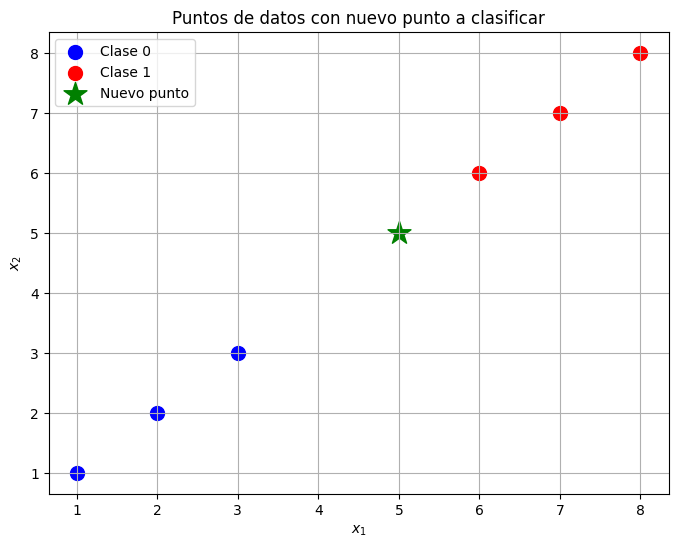

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Datos de entrenamiento
X = np.array([[1, 1], [2, 2], [3, 3], [6, 6], [7, 7], [8, 8]])
y = np.array([0, 0, 0, 1, 1, 1])

# Nuevo punto a clasificar
x_new = np.array([5, 5])

plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='blue', label='Clase 0', s=100)
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='red', label='Clase 1', s=100)
plt.scatter(x_new[0], x_new[1], color='green', marker='*', s=300, label='Nuevo punto')
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title('Puntos de datos con nuevo punto a clasificar')
plt.grid(True)
plt.legend()
plt.show()

## ¿Cómo decide KNN la clase de un nuevo punto?

Al ver los datos anteriores, puede surgir una pregunta: **¿cómo sabe el algoritmo a qué clase asignar el nuevo punto?** La respuesta está en medir **qué tan cerca** está el nuevo punto de los puntos conocidos.

Pero... **¿qué significa "cerca"?** Necesitamos una forma de medir la distancia entre dos puntos.

## Demostración Matemática

### Paso 1: Medir la distancia

La métrica de distancia más utilizada en KNN es la **distancia euclidiana**. Es la distancia en "línea recta" entre dos puntos, y es una generalización del teorema de Pitágoras a $n$ dimensiones.

Para dos puntos $\mathbf{a} = (a_1, a_2, \dots, a_n)$ y $\mathbf{b} = (b_1, b_2, \dots, b_n)$ en un espacio de $n$ dimensiones, la distancia euclidiana se define como:

$$
d(\mathbf{a}, \mathbf{b}) = \sqrt{\sum_{j=1}^{n} (a_j - b_j)^2}
$$

En el caso de dos dimensiones ($n = 2$), esto se reduce a la fórmula clásica:

$$
d(\mathbf{a}, \mathbf{b}) = \sqrt{(a_1 - b_1)^2 + (a_2 - b_2)^2}
$$

Que no es otra cosa que el **teorema de Pitágoras** aplicado al triángulo rectángulo formado por los dos puntos.

**¿Por qué elevar al cuadrado y luego sacar la raíz?**

- Elevamos al cuadrado para **eliminar los signos negativos** (las diferencias pueden ser positivas o negativas).
- Sacamos la raíz cuadrada para que el resultado **tenga las mismas unidades** que los datos originales.

Existen otras métricas de distancia (Manhattan, Minkowski, etc.), pero la euclidiana es la más común y la que usaremos en esta implementación.

### Paso 2: Encontrar los $k$ vecinos más cercanos

Una vez que sabemos cómo medir distancias, el siguiente paso es:

1. Calcular la distancia entre el nuevo punto $\mathbf{x}$ y **cada uno** de los $n$ puntos de entrenamiento $\mathbf{x}_1, \mathbf{x}_2, \dots, \mathbf{x}_n$.
2. **Ordenar** estas distancias de menor a mayor.
3. Seleccionar los **$k$ puntos con las distancias más pequeñas**.

Matemáticamente, buscamos el conjunto:

$$
N_k(\mathbf{x}) = \{\mathbf{x}_{(1)}, \mathbf{x}_{(2)}, \dots, \mathbf{x}_{(k)}\}
$$

Donde $\mathbf{x}_{(1)}$ es el punto más cercano, $\mathbf{x}_{(2)}$ el segundo más cercano, y así sucesivamente hasta $\mathbf{x}_{(k)}$.

Es decir:

$$
d(\mathbf{x}, \mathbf{x}_{(1)}) \leq d(\mathbf{x}, \mathbf{x}_{(2)}) \leq \dots \leq d(\mathbf{x}, \mathbf{x}_{(k)}) \leq d(\mathbf{x}, \mathbf{x}_{(j)}) \quad \forall j > k
$$

### Paso 3: Votar por la clase

Una vez que tenemos los $k$ vecinos más cercanos, necesitamos decidir qué clase asignar al nuevo punto. El método más simple es el **voto por mayoría**:

$$
\hat{y} = \text{moda}\{y_{(1)}, y_{(2)}, \dots, y_{(k)}\}
$$

Donde $y_{(i)}$ es la etiqueta de clase del $i$-ésimo vecino más cercano.

En otras palabras, **contamos cuántos vecinos pertenecen a cada clase y asignamos la clase con más votos**.

Por ejemplo, si $k = 3$ y los tres vecinos más cercanos tienen clases $\{0, 1, 1\}$, entonces la clase predicha es $\hat{y} = 1$ (porque 1 tiene 2 votos vs. 1 voto de la clase 0).

### La importancia de $k$

El valor de $k$ es el **hiperparámetro** más importante de KNN:

- **$k$ muy pequeño** (ej. $k = 1$): el modelo es muy sensible al ruido. Un solo punto atípico puede cambiar la predicción. Esto se conoce como **sobreajuste** (overfitting).
- **$k$ muy grande** (ej. $k = n$): el modelo asigna siempre la clase mayoritaria del dataset completo, ignorando la estructura local. Esto se conoce como **subajuste** (underfitting).

En la práctica, se suelen probar varios valores de $k$ y seleccionar el que mejor funcione (por ejemplo, usando validación cruzada). Un consejo común es usar **$k$ impar** cuando hay dos clases, para evitar empates.

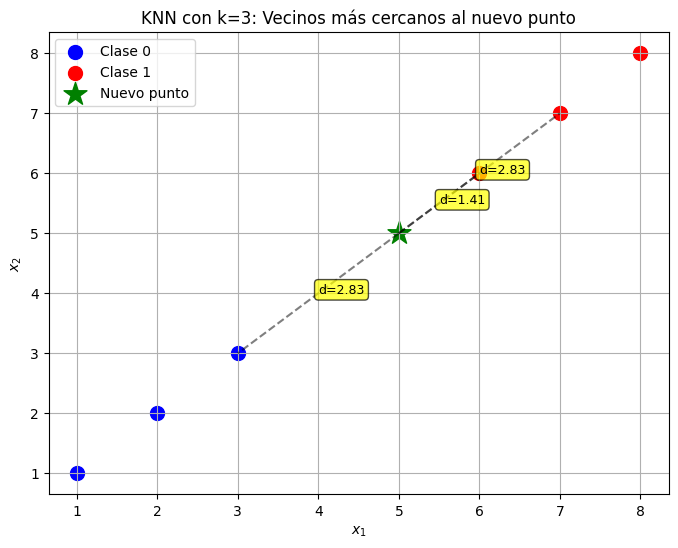

Distancias: ['5.66', '4.24', '2.83', '1.41', '2.83', '4.24']
Índices de los 3 vecinos más cercanos: [3 2 4]
Clases de los vecinos: [np.int64(1), np.int64(0), np.int64(1)]
Clase predicha (moda): 1


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Datos de entrenamiento
X = np.array([[1, 1], [2, 2], [3, 3], [6, 6], [7, 7], [8, 8]])
y = np.array([0, 0, 0, 1, 1, 1])
x_new = np.array([5, 5])

# Calcular distancias
distances = [np.sqrt(np.sum((x_new - x_i) ** 2)) for x_i in X]
k = 3
k_idx = np.argsort(distances)[:k]

plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='blue', label='Clase 0', s=100)
plt.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='red', label='Clase 1', s=100)
plt.scatter(x_new[0], x_new[1], color='green', marker='*', s=300, label='Nuevo punto')

# Dibujar líneas a los k vecinos más cercanos
for idx in k_idx:
    plt.plot([x_new[0], X[idx][0]], [x_new[1], X[idx][1]], 'k--', alpha=0.5)
    mid_x = (x_new[0] + X[idx][0]) / 2
    mid_y = (x_new[1] + X[idx][1]) / 2
    plt.annotate(f'd={distances[idx]:.2f}', (mid_x, mid_y), fontsize=9,
                 bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7))

plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.title(f'KNN con k={k}: Vecinos más cercanos al nuevo punto')
plt.grid(True)
plt.legend()
plt.show()

print(f"Distancias: {[f'{d:.2f}' for d in distances]}")
print(f"Índices de los {k} vecinos más cercanos: {k_idx}")
print(f"Clases de los vecinos: {[y[i] for i in k_idx]}")
print(f"Clase predicha (moda): {max(set([y[i] for i in k_idx]), key=[y[i] for i in k_idx].count)}")

### Ejemplo numérico

Dado el conjunto de entrenamiento:

| $x_1$ | $x_2$ | Clase |
|-------|-------|-------|
| 1     | 1     | 0     |
| 2     | 2     | 0     |
| 3     | 3     | 0     |
| 6     | 6     | 1     |
| 7     | 7     | 1     |
| 8     | 8     | 1     |

Queremos clasificar el nuevo punto $\mathbf{x} = (5, 5)$ con $k = 3$.

**Paso 1: Calcular distancias**

$$
d(\mathbf{x}, \mathbf{x}_1) = \sqrt{(5-1)^2 + (5-1)^2} = \sqrt{16 + 16} = \sqrt{32} \approx 5.66
$$

$$
d(\mathbf{x}, \mathbf{x}_2) = \sqrt{(5-2)^2 + (5-2)^2} = \sqrt{9 + 9} = \sqrt{18} \approx 4.24
$$

$$
d(\mathbf{x}, \mathbf{x}_3) = \sqrt{(5-3)^2 + (5-3)^2} = \sqrt{4 + 4} = \sqrt{8} \approx 2.83
$$

$$
d(\mathbf{x}, \mathbf{x}_4) = \sqrt{(5-6)^2 + (5-6)^2} = \sqrt{1 + 1} = \sqrt{2} \approx 1.41
$$

$$
d(\mathbf{x}, \mathbf{x}_5) = \sqrt{(5-7)^2 + (5-7)^2} = \sqrt{4 + 4} = \sqrt{8} \approx 2.83
$$

$$
d(\mathbf{x}, \mathbf{x}_6) = \sqrt{(5-8)^2 + (5-8)^2} = \sqrt{9 + 9} = \sqrt{18} \approx 4.24
$$

**Paso 2: Ordenar y seleccionar los $k = 3$ más cercanos**

| Vecino    | Distancia | Clase |
|-----------|-----------|-------|
| $\mathbf{x}_4 = (6,6)$ | 1.41 | 1 |
| $\mathbf{x}_3 = (3,3)$ | 2.83 | 0 |
| $\mathbf{x}_5 = (7,7)$ | 2.83 | 1 |

**Paso 3: Votar**

- Clase 0: **1 voto**
- Clase 1: **2 votos**

$$
\boxed{\hat{y} = 1}
$$

El nuevo punto $(5, 5)$ es clasificado como **Clase 1**.

## Implementación con Código

### Funciones

In [ ]:
from collections import Counter
import numpy as np

def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

def knn_predict(X_train, y_train, x, k=3):
    # Calcular distancias entre x y todos los puntos de entrenamiento
    distances = [euclidean_distance(x, x_train) for x_train in X_train]
    # Ordenar por distancia y obtener los índices de los k más cercanos
    k_idx = np.argsort(distances)[:k]
    # Extraer las etiquetas de los k vecinos más cercanos
    k_neighbor_labels = [y_train[i] for i in k_idx]
    # Retornar la clase más común
    most_common = Counter(k_neighbor_labels).most_common(1)
    return most_common[0][0]

def knn_predict_batch(X_train, y_train, X_test, k=3):
    return np.array([knn_predict(X_train, y_train, x, k) for x in X_test])

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

# Cargar datos
iris = datasets.load_iris()
X, y = iris.data, iris.target

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

# Predecir
k = 3
predictions = knn_predict_batch(X_train, y_train, X_test, k=k)

# Accuracy
accuracy = np.sum(y_test == predictions) / len(y_test)
print(f"KNN (k={k}) accuracy: {accuracy:.4f}")

KNN (k=3) accuracy: 1.0000


### Clase

In [ ]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


class KNN:
    def __init__(self, k=3):
        self.k = k

    def fit(self, X, y):
        """Almacena los datos de entrenamiento (algoritmo lazy)"""
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def predict(self, X):
        """Predice la clase para cada punto en X"""
        X = np.array(X)
        y_pred = [self._predict(x) for x in X]
        return np.array(y_pred)

    def _predict(self, x):
        """Predice la clase de un solo punto"""
        # Calcular distancias entre x y todos los puntos de entrenamiento
        distances = [self._euclidean_distance(x, x_train) for x_train in self.X_train]
        # Ordenar por distancia y obtener los índices de los k más cercanos
        k_idx = np.argsort(distances)[:self.k]
        # Extraer las etiquetas de los k vecinos más cercanos
        k_neighbor_labels = [self.y_train[i] for i in k_idx]
        # Retornar la clase más común
        most_common = Counter(k_neighbor_labels).most_common(1)
        return most_common[0][0]

    @staticmethod
    def _euclidean_distance(x1, x2):
        return np.sqrt(np.sum((x1 - x2) ** 2))

    def score(self, X, y):
        """Calcula la accuracy del modelo"""
        predictions = self.predict(X)
        return np.sum(predictions == y) / len(y)

    def plot_decision_boundary(self, X, y, title="Frontera de decisión KNN", feature_indices=(0, 1)):
        """Grafica la frontera de decisión usando dos features"""
        i, j = feature_indices
        X_2d = X[:, [i, j]]

        # Reentrenar con solo 2 features para la visualización
        temp_knn = KNN(k=self.k)
        temp_knn.fit(X_2d, y)

        h = 0.1  # paso de la malla
        x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
        y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
        xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                             np.arange(y_min, y_max, h))

        Z = temp_knn.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)

        cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
        cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

        plt.figure(figsize=(8, 6))
        plt.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
        plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap=cmap_bold, edgecolors='k', s=60)
        plt.xlabel(f'Feature {i}')
        plt.ylabel(f'Feature {j}')
        plt.title(f'{title} (k={self.k})')
        plt.grid(True, alpha=0.3)
        plt.show()

KNN (k=3) accuracy: 1.0000


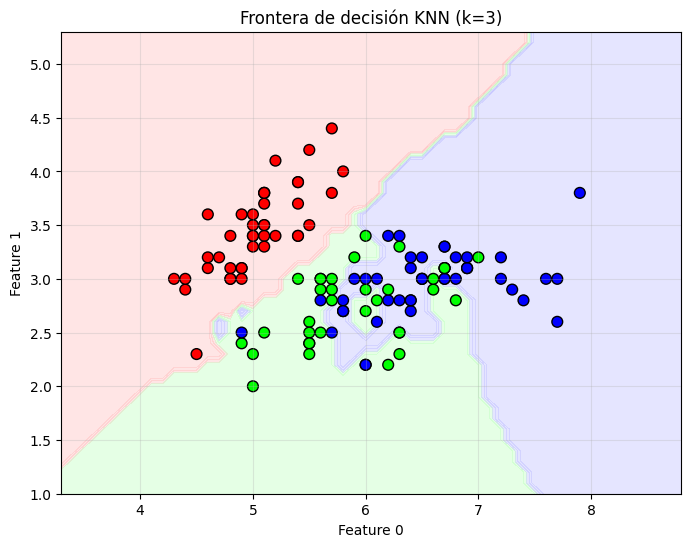

In [ ]:
from sklearn import datasets
from sklearn.model_selection import train_test_split

# Cargar datos
iris = datasets.load_iris()
X, y = iris.data, iris.target

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234
)

# Crear y ajustar modelo
k = 3
model = KNN(k=k)
model.fit(X_train, y_train)

# Predecir y evaluar
predictions = model.predict(X_test)
acc = model.score(X_test, y_test)
print(f"KNN (k={k}) accuracy: {acc:.4f}")

# Visualizar frontera de decisión
model.plot_decision_boundary(X_train, y_train)

In [ ]:
# Comparar diferentes valores de k
print("Comparación de diferentes valores de k:\n")
for k in [1, 3, 5, 7, 9]:
    model = KNN(k=k)
    model.fit(X_train, y_train)
    acc = model.score(X_test, y_test)
    print(f"  k = {k}: accuracy = {acc:.4f}")

Comparación de diferentes valores de k:

  k = 1: accuracy = 1.0000
  k = 3: accuracy = 1.0000
  k = 5: accuracy = 0.9667
  k = 7: accuracy = 0.9667
  k = 9: accuracy = 1.0000
